# KITTI Obstacle Detection: Data Acquisition, Preprocessing and EDA
 **Project:** Camera-Based Obstacle Detection for Driver Assistance

**Pipeline in this notebook**
1. Setup and data layout
2. Validation of images and labels
3. Label parsing and label engineering (KITTI Easy / Moderate / Hard)
4. Exploratory data analysis
5. Input-resolution analysis (small-object study)
6. Drive-grouped split (leakage-free) plus a random split for RQ3
7. Leakage demonstration
8. Export to YOLO format and a flat annotation table (for Faster R-CNN / torchvision)
9. Augmentation preview (fog, rain, low light) for RQ4

**Outputs** (written to `outputs/`): `images.csv`, `annotations.csv`, `splits.csv`, `eda_summary.json`, plus a `yolo/` dataset folder.

## 0. Setup
Install once (if needed):
```
pip install pandas numpy matplotlib opencv-python pillow albumentations tqdm pyyaml scikit-learn
```

In [ ]:
!pip install pandas numpy matplotlib opencv-python pillow albumentations tqdm pyyaml scikit-learn



In [ ]:
import torchvision
torchvision.datasets.Kitti(root="/content/kitti", train=True, download=True)

100%|██████████| 12.6G/12.6G [06:00<00:00, 34.9MB/s]
100%|██████████| 5.60M/5.60M [00:00<00:00, 7.14MB/s]


Dataset Kitti
    Number of datapoints: 7481
    Root location: /content/kitti

In [ ]:
!unzip -q data/devkit_object.zip -d data/Kitti/raw/devkit

In [ ]:
import json, shutil, os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)

# ---- paths: edit DATA_ROOT to wherever you unzipped KITTI ----
DATA_ROOT = Path("data/Kitti/raw")
IMG_DIR   = DATA_ROOT / "training" / "image_2"
LBL_DIR   = DATA_ROOT / "training" / "label_2"
OUT_DIR   = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

# Mapping files come from the KITTI object devkit (data_object_devkit.zip).
# We search for them so the exact unzip folder name does not matter.
def find_one(name):
    hits = list(DATA_ROOT.rglob(name))
    return hits[0] if hits else None
MAP_FILE  = find_one("train_mapping.txt")
RAND_FILE = find_one("train_rand.txt")

CLASSES = ["Car", "Pedestrian", "Van", "Cyclist", "Truck", "Misc", "Tram", "Person_sitting"]
FOCUS   = ["Car", "Pedestrian", "Cyclist"]          # primary-metric classes
COMPUTE_IMAGE_STATS = True                           # set False to skip the ~1-2 min pixel pass

print("Images dir :", IMG_DIR, IMG_DIR.exists())
print("Labels dir :", LBL_DIR, LBL_DIR.exists())
print("Mapping    :", MAP_FILE)
print("Rand file  :", RAND_FILE)

Images dir : data/Kitti/raw/training/image_2 True
Labels dir : data/Kitti/raw/training/label_2 True
Mapping    : data/Kitti/raw/devkit/mapping/train_mapping.txt
Rand file  : data/Kitti/raw/devkit/mapping/train_rand.txt


## 1. File integrity checks

In [ ]:
img_files = sorted(IMG_DIR.glob("*.png"))
lbl_files = sorted(LBL_DIR.glob("*.txt"))
img_ids, lbl_ids = {p.stem for p in img_files}, {p.stem for p in lbl_files}

print(f"images: {len(img_ids)} | label files: {len(lbl_ids)}")
print("images without labels :", len(img_ids - lbl_ids))
print("labels without images :", len(lbl_ids - img_ids))
assert len(img_ids) > 0, "No images found - check DATA_ROOT"
assert MAP_FILE is not None and RAND_FILE is not None, "Devkit mapping files not found - see acquisition cell"

images: 7481 | label files: 7481
images without labels : 0
labels without images : 0


In [ ]:
# Per-image table: size, decodability, brightness (needed for the low-light discussion in RQ4)
records = []
for p in tqdm(img_files, desc="scanning images"):
    rec = {"image_id": p.stem}
    try:
        with Image.open(p) as im:
            rec["width"], rec["height"] = im.size
        if COMPUTE_IMAGE_STATS:
            g = cv2.imread(str(p), cv2.IMREAD_REDUCED_GRAYSCALE_4)   # fast, 4x downsampled decode
            rec["corrupt"] = g is None
            if g is not None:
                rec["brightness"] = float(g.mean())
                rec["contrast"]   = float(g.std())
        else:
            rec["corrupt"] = False
    except Exception as e:
        rec["corrupt"] = True
    records.append(rec)
images = pd.DataFrame(records)
print("corrupt images:", int(images["corrupt"].sum()))
print(images.groupby(["width", "height"]).size().rename("n_images").reset_index())
images.describe()

scanning images:   0%|          | 0/7481 [00:00<?, ?it/s]

corrupt images: 0
   width  height  n_images
0   1224     370       770
1   1238     374       358
2   1241     376       296
3   1242     375      6057


,width,height,brightness,contrast
count,7481.000000,7481.000000,7481.000000,7481.000000
mean,1239.916321,374.477075,96.502049,78.434151
std,5.460402,1.545146,13.383794,8.121181
min,1224.000000,370.000000,70.077523,53.163696
25%,1242.000000,375.000000,89.250309,72.503376
50%,1242.000000,375.000000,92.543427,78.106293
75%,1242.000000,375.000000,98.483316,84.008026
max,1242.000000,376.000000,180.147381,105.382296


## 2. Parse labels
KITTI label format (15 fields per object): `type, truncated, occluded, alpha, x1, y1, x2, y2, h3d, w3d, l3d, x3d, y3d, z3d, rotation_y`.
Only the class and the 2D box matter for detection; 3D fields are kept for EDA (e.g. distance `z3d`).
`DontCare` marks regions that were not labelled; we keep them separately as **ignore regions**.

In [ ]:
COLS = ["type", "truncated", "occluded", "alpha", "x1", "y1", "x2", "y2",
        "h3d", "w3d", "l3d", "x3d", "y3d", "z3d", "rot_y"]
rows, malformed = [], []
for p in tqdm(lbl_files, desc="parsing labels"):
    for ln, line in enumerate(p.read_text().splitlines()):
        parts = line.split()
        if len(parts) < 15:
            malformed.append((p.stem, ln, line)); continue
        rows.append([p.stem] + parts[:15])

raw = pd.DataFrame(rows, columns=["image_id"] + COLS)
num_cols = [c for c in COLS if c != "type"]
raw[num_cols] = raw[num_cols].apply(pd.to_numeric, errors="coerce")
raw["occluded"] = raw["occluded"].astype(int)

print("malformed lines:", len(malformed))
print("NaNs in numeric columns:", int(raw[num_cols].isna().sum().sum()))
print("total rows (incl. DontCare):", len(raw))
print(raw["type"].value_counts())

parsing labels:   0%|          | 0/7481 [00:00<?, ?it/s]

malformed lines: 0
NaNs in numeric columns: 0
total rows (incl. DontCare): 51865
type
Car               28742
DontCare          11295
Pedestrian         4487
Van                2914
Cyclist            1627
Truck              1094
Misc                973
Tram                511
Person_sitting      222
Name: count, dtype: int64


In [ ]:
# Split real objects from DontCare ignore regions
ignore_regions = raw[raw["type"] == "DontCare"].copy()
objs = raw[raw["type"].isin(CLASSES)].copy()
other = sorted(set(raw["type"]) - set(CLASSES) - {"DontCare"})
print("objects:", len(objs), "| ignore regions:", len(ignore_regions), "| unexpected classes:", other)

objs = objs.merge(images[["image_id", "width", "height"]], on="image_id", how="left")
objs["bw"] = objs["x2"] - objs["x1"]
objs["bh"] = objs["y2"] - objs["y1"]
objs["area"] = objs["bw"] * objs["bh"]
objs["aspect"] = objs["bw"] / objs["bh"]
objs["cx"] = (objs["x1"] + objs["x2"]) / 2 / objs["width"]
objs["cy"] = (objs["y1"] + objs["y2"]) / 2 / objs["height"]

# ---- validation checks ----
checks = {
    "x2 <= x1 or y2 <= y1":      int(((objs.x2 <= objs.x1) | (objs.y2 <= objs.y1)).sum()),
    "box outside image (>2px)":  int(((objs.x1 < -2) | (objs.y1 < -2) | (objs.x2 > objs.width + 2) | (objs.y2 > objs.height + 2)).sum()),
    "truncated outside [0,1]":   int(((objs.truncated < 0) | (objs.truncated > 1)).sum()),
    "occluded not in {0,1,2,3}": int((~objs.occluded.isin([0, 1, 2, 3])).sum()),
    "exact duplicate rows":      int(objs.duplicated().sum()),
}
pd.Series(checks, name="count")

objects: 40570 | ignore regions: 11295 | unexpected classes: []


,count
x2 <= x1 or y2 <= y1,0
box outside image (>2px),0
"truncated outside [0,1]",0
"occluded not in {0,1,2,3}",0
exact duplicate rows,0


In [ ]:
# Compare against the numbers quoted in the proposal
proposal = {"Car": 28742, "Pedestrian": 4487, "Van": 2914, "Cyclist": 1627,
            "Truck": 1094, "Misc": 973, "Tram": 511, "Person_sitting": 222}
cmp = pd.DataFrame({"proposal": pd.Series(proposal), "observed": objs["type"].value_counts()})
cmp["diff"] = cmp["observed"] - cmp["proposal"]
print("total objects observed:", len(objs), "(proposal: 40,570)")
cmp

total objects observed: 40570 (proposal: 40,570)


,proposal,observed,diff
Car,28742,28742,0
Pedestrian,4487,4487,0
Van,2914,2914,0
Cyclist,1627,1627,0
Truck,1094,1094,0
Misc,973,973,0
Tram,511,511,0
Person_sitting,222,222,0


## 3. Label engineering: KITTI difficulty levels
Official KITTI definitions (used for the *Moderate* primary metric):

| Level | Min box height | Max occlusion | Max truncation |
|---|---|---|---|
| Easy | 40 px | 0 (fully visible) | 15% |
| Moderate | 25 px | 1 (partly occluded) | 30% |
| Hard | 25 px | 2 (largely occluded) | 50% |

Levels are cumulative: every Easy object is also Moderate and Hard.

In [ ]:
objs["is_easy"]     = (objs.bh >= 40) & (objs.occluded <= 0) & (objs.truncated <= 0.15)
objs["is_moderate"] = (objs.bh >= 25) & (objs.occluded <= 1) & (objs.truncated <= 0.30)
objs["is_hard"]     = (objs.bh >= 25) & (objs.occluded <= 2) & (objs.truncated <= 0.50)

def hardest_bin(r):
    if r.is_easy: return "Easy"
    if r.is_moderate: return "Moderate"
    if r.is_hard: return "Hard"
    return "Unrated"
objs["difficulty"] = objs.apply(hardest_bin, axis=1)

diff_tab = pd.crosstab(objs["type"], objs["difficulty"]).reindex(columns=["Easy", "Moderate", "Hard", "Unrated"], fill_value=0)
diff_tab["total"] = diff_tab.sum(axis=1)
diff_tab = diff_tab.loc[CLASSES]
print("Exclusive difficulty bins (an object appears in its easiest bin only)")
diff_tab

Exclusive difficulty bins (an object appears in its easiest bin only)


difficulty,Easy,Moderate,Hard,Unrated,total
type,,,,,
Car,5971,9739,6006,7026,28742
Pedestrian,2310,1259,707,211,4487
Van,378,920,675,941,2914
Cyclist,654,444,96,433,1627
Truck,253,469,110,262,1094
Misc,255,334,178,206,973
Tram,139,138,127,107,511
Person_sitting,39,70,80,33,222


## 4. Exploratory data analysis

### 4.1 Class distribution (imbalance)

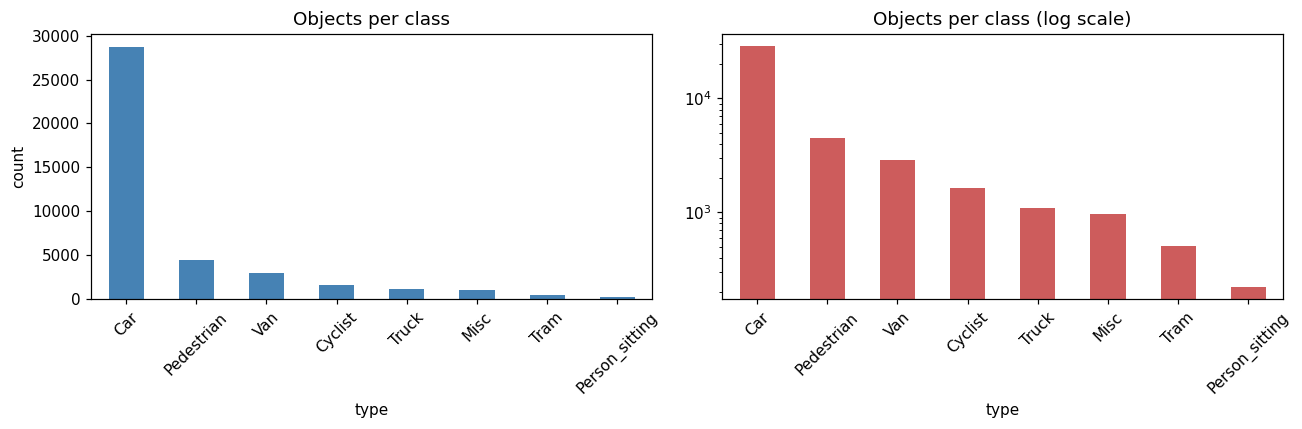

                count  share_%
type                          
Car             28742    70.85
Pedestrian       4487    11.06
Van              2914     7.18
Cyclist          1627     4.01
Truck            1094     2.70
Misc              973     2.40
Tram              511     1.26
Person_sitting    222     0.55

Imbalance ratio Car : Person_sitting = 129 : 1


In [ ]:
counts = objs["type"].value_counts().reindex(CLASSES)
share = (counts / counts.sum() * 100).round(2)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
counts.plot.bar(ax=ax[0], color="steelblue"); ax[0].set_title("Objects per class"); ax[0].set_ylabel("count")
counts.plot.bar(ax=ax[1], color="indianred", logy=True); ax[1].set_title("Objects per class (log scale)")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"count": counts, "share_%": share}))
print(f"\nImbalance ratio Car : Person_sitting = {counts['Car'] / counts['Person_sitting']:.0f} : 1")

### 4.2 Objects per image and class presence

count    7481.000000
mean        5.423072
std         3.738047
min         1.000000
25%         2.000000
50%         5.000000
75%         7.000000
max        22.000000
dtype: float64
images with zero objects: 0

Images containing at least one object of each class:
type
Car               6684
Pedestrian        1779
Van               2145
Cyclist           1141
Truck             1036
Misc               778
Tram               349
Person_sitting      99
Name: n_images, dtype: int64


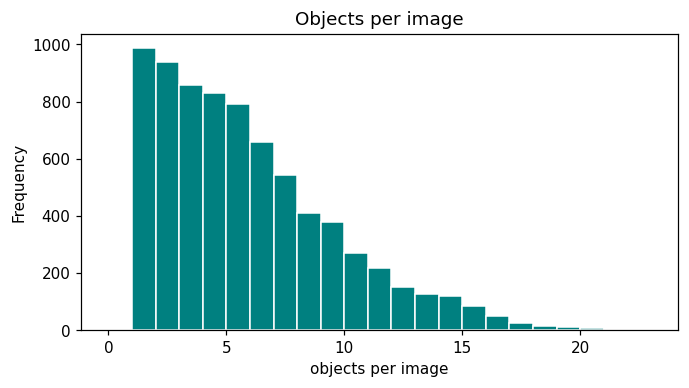

In [ ]:
per_img = objs.groupby("image_id").size().reindex(images["image_id"], fill_value=0)
print(per_img.describe())
print("images with zero objects:", int((per_img == 0).sum()))

presence = pd.crosstab(objs["image_id"], objs["type"]).reindex(images["image_id"], fill_value=0).reindex(columns=CLASSES, fill_value=0)
print("\nImages containing at least one object of each class:")
print((presence > 0).sum().rename("n_images"))

fig, ax = plt.subplots(figsize=(7, 3.5))
per_img.plot.hist(bins=range(0, int(per_img.max()) + 2), ax=ax, color="teal", edgecolor="white")
ax.set_xlabel("objects per image"); ax.set_title("Objects per image"); plt.show()

### 4.3 Box size and aspect ratio (small-object problem)

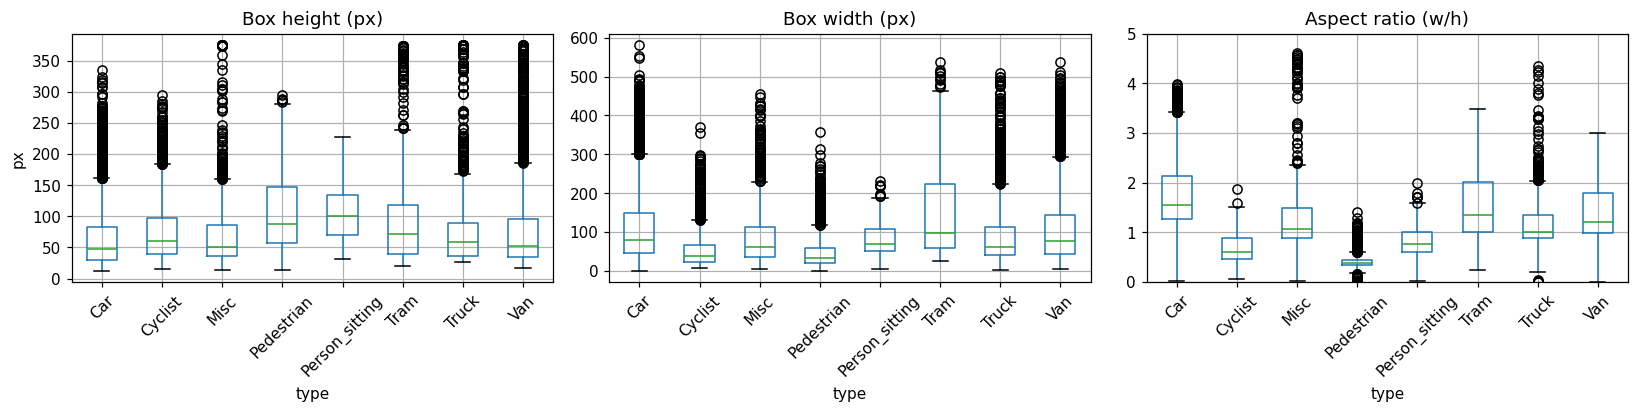

bh                        bw        area
                   10%      50%      90%     50%         50%
type                                                        
Car             22.460   46.990  156.105  79.700  3708.52160
Pedestrian      40.712   87.890  188.262  33.330  2927.08080
Van             27.100   52.980  191.622  75.720  4004.26650
Cyclist         28.786   60.050  162.268  37.940  2387.37840
Truck           29.913   59.295  178.704  60.905  3607.03185
Misc            26.734   51.260  147.814  61.790  3198.27060
Tram            31.900   72.220  242.500  96.410  7867.72320
Person_sitting  54.869  100.120  151.266  69.660  6621.02315

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
order = CLASSES
objs.boxplot(column="bh", by="type", ax=ax[0], rot=45); ax[0].set_title("Box height (px)"); ax[0].set_ylabel("px")
objs.boxplot(column="bw", by="type", ax=ax[1], rot=45); ax[1].set_title("Box width (px)")
objs.boxplot(column="aspect", by="type", ax=ax[2], rot=45); ax[2].set_title("Aspect ratio (w/h)"); ax[2].set_ylim(0, 5)
plt.suptitle(""); plt.tight_layout(); plt.show()

size_stats = objs.groupby("type")[["bh", "bw", "area"]].describe(percentiles=[.1, .5, .9]).loc[CLASSES]
size_stats[[("bh", "10%"), ("bh", "50%"), ("bh", "90%"), ("bw", "50%"), ("area", "50%")]]

### 4.4 Where do objects appear in the frame?

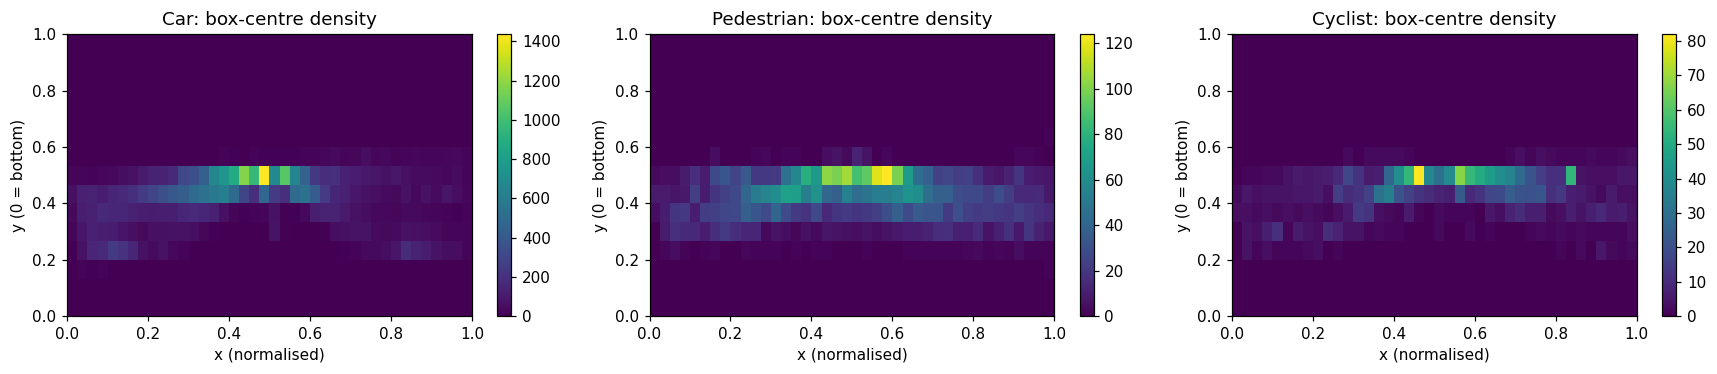

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for a, c in zip(axes, FOCUS):
    s = objs[objs["type"] == c]
    h = a.hist2d(s.cx, 1 - s.cy, bins=[40, 15], range=[[0, 1], [0, 1]], cmap="viridis")
    a.set_title(f"{c}: box-centre density"); a.set_xlabel("x (normalised)"); a.set_ylabel("y (0 = bottom)")
    plt.colorbar(h[3], ax=a)
plt.tight_layout(); plt.show()

### 4.5 Occlusion, truncation and distance

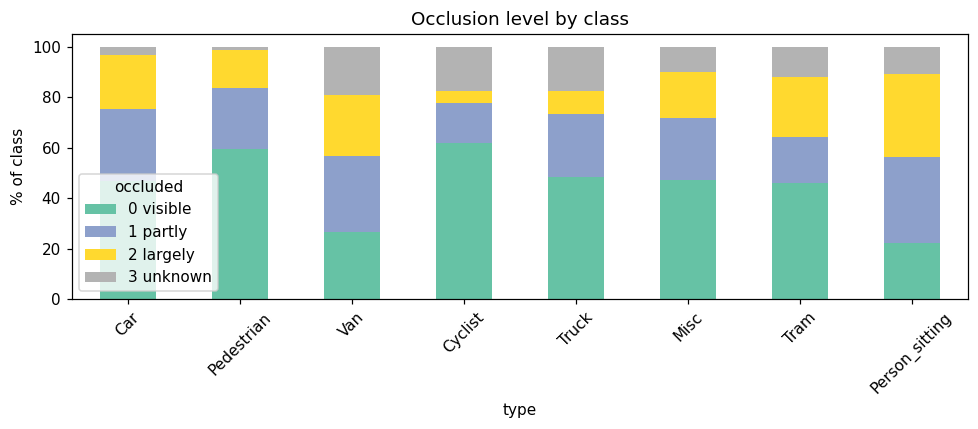

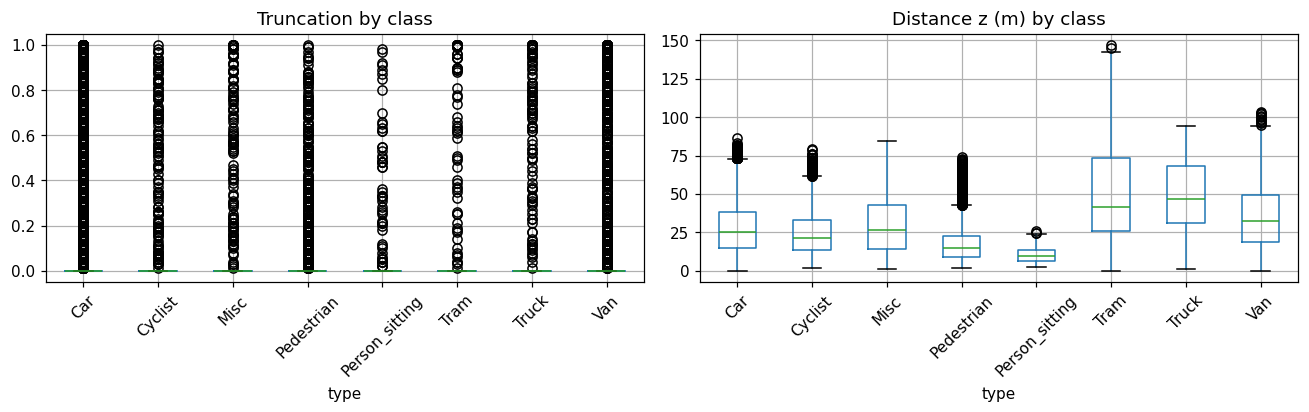

In [ ]:
occ_names = {0: "0 visible", 1: "1 partly", 2: "2 largely", 3: "3 unknown"}
occ_tab = pd.crosstab(objs["type"], objs["occluded"].map(occ_names), normalize="index").loc[CLASSES] * 100
occ_tab.round(1).plot.bar(stacked=True, figsize=(9, 4), colormap="Set2")
plt.ylabel("% of class"); plt.title("Occlusion level by class"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
objs.boxplot(column="truncated", by="type", ax=ax[0], rot=45); ax[0].set_title("Truncation by class")
objs[objs.z3d > 0].boxplot(column="z3d", by="type", ax=ax[1], rot=45); ax[1].set_title("Distance z (m) by class")
plt.suptitle(""); plt.tight_layout(); plt.show()

### 4.6 Difficulty mix

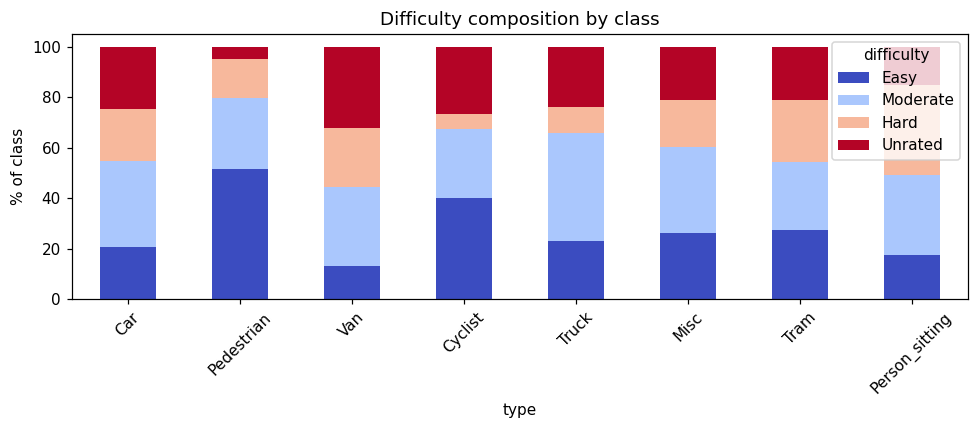

Objects evaluated under the primary metric (Moderate or easier, focus classes):
type
Car           15710
Pedestrian     3569
Cyclist        1098
Name: count, dtype: int64


In [ ]:
(diff_tab.drop(columns="total").div(diff_tab["total"], axis=0) * 100).round(1).plot.bar(stacked=True, figsize=(9, 4), colormap="coolwarm")
plt.ylabel("% of class"); plt.title("Difficulty composition by class"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

mod = objs[objs.is_moderate & objs["type"].isin(FOCUS)]
print("Objects evaluated under the primary metric (Moderate or easier, focus classes):")
print(mod["type"].value_counts())

### 4.7 Image-level statistics (lighting)

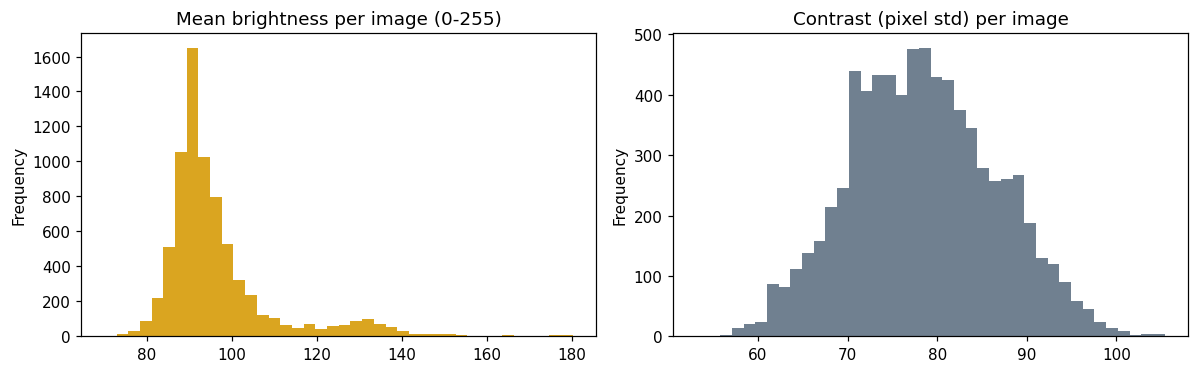

       brightness  contrast
count      7481.0    7481.0
mean         96.5      78.4
std          13.4       8.1
min          70.1      53.2
25%          89.3      72.5
50%          92.5      78.1
75%          98.5      84.0
max         180.1     105.4

Darkest images (candidate hard cases):
     image_id  brightness
5693   005693   70.077523
6669   006669   70.987548
3640   003640   71.051925
823    000823   72.068366
3928   003928   72.833715


In [ ]:
if COMPUTE_IMAGE_STATS:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    images["brightness"].plot.hist(bins=40, ax=ax[0], color="goldenrod"); ax[0].set_title("Mean brightness per image (0-255)")
    images["contrast"].plot.hist(bins=40, ax=ax[1], color="slategray"); ax[1].set_title("Contrast (pixel std) per image")
    plt.tight_layout(); plt.show()
    print(images[["brightness", "contrast"]].describe().round(1))
    print("\nDarkest images (candidate hard cases):")
    print(images.nsmallest(5, "brightness")[["image_id", "brightness"]])

### 4.8 Sample images with ground truth

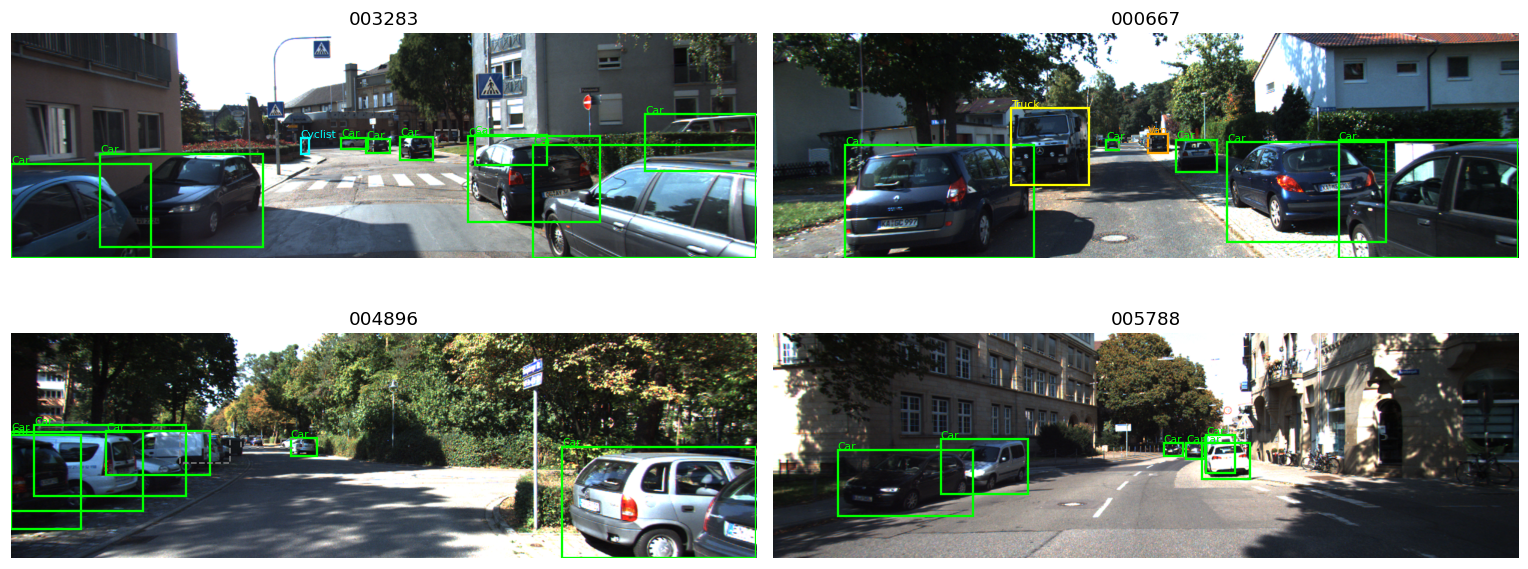

In [ ]:
COLORS = {"Car": "lime", "Pedestrian": "red", "Cyclist": "cyan", "Van": "orange",
          "Truck": "yellow", "Misc": "magenta", "Tram": "white", "Person_sitting": "pink"}

def show_image(image_id, ax=None, show_ignore=True):
    img = cv2.cvtColor(cv2.imread(str(IMG_DIR / f"{image_id}.png")), cv2.COLOR_BGR2RGB)
    if ax is None: _, ax = plt.subplots(figsize=(12, 4))
    ax.imshow(img); ax.axis("off"); ax.set_title(image_id)
    for r in objs[objs.image_id == image_id].itertuples():
        ax.add_patch(patches.Rectangle((r.x1, r.y1), r.bw, r.bh, fill=False, ec=COLORS[r.type], lw=1.5))
        ax.text(r.x1, r.y1 - 2, r.type, color=COLORS[r.type], fontsize=7)
    if show_ignore:
        for r in ignore_regions[ignore_regions.image_id == image_id].itertuples():
            ax.add_patch(patches.Rectangle((r.x1, r.y1), r.x2 - r.x1, r.y2 - r.y1, fill=False, ec="gray", ls="--", lw=1))

rng = np.random.default_rng(SEED)
sample_ids = list(rng.choice(images["image_id"], 4, replace=False))
fig, axes = plt.subplots(2, 2, figsize=(14, 6))
for a, i in zip(axes.ravel(), sample_ids): show_image(i, a)
plt.tight_layout(); plt.show()

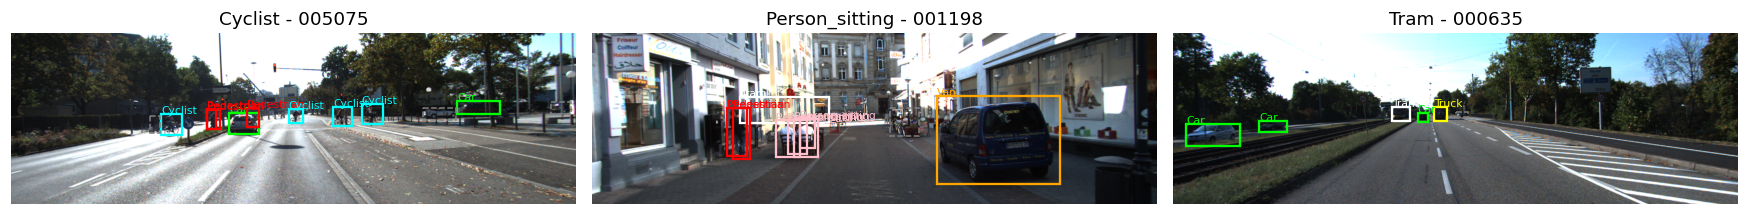

In [ ]:
# Rare-class examples: images with Cyclist / Person_sitting / Tram
fig, axes = plt.subplots(1, 3, figsize=(16, 3))
for a, c in zip(axes, ["Cyclist", "Person_sitting", "Tram"]):
    i = rng.choice(objs[objs["type"] == c]["image_id"].unique())
    show_image(i, a); a.set_title(f"{c} - {i}")
plt.tight_layout(); plt.show()

## 5. Input-resolution analysis
KITTI images are ~1242x375, and the RTX 3050 has 4 GB of VRAM. If we resize the image width to `W`, every box shrinks by `W / 1242`.
Detectors struggle below roughly 8-16 px, so this shows what fraction of **Moderate-level** Pedestrians and Cyclists would fall below those sizes at each input width.

 input_width      class  median_h_px  %_below_8px  %_below_16px
         480        Car         19.1          0.0          38.1
         480 Pedestrian         35.3          0.0           8.8
         480    Cyclist         23.8          0.0          22.7
         640        Car         25.4          0.0          16.6
         640 Pedestrian         47.1          0.0           2.1
         640    Cyclist         31.7          0.0           7.7
         800        Car         31.8          0.0           0.0
         800 Pedestrian         58.8          0.0           0.0
         800    Cyclist         39.6          0.0           0.0
         960        Car         38.1          0.0           0.0
         960 Pedestrian         70.6          0.0           0.0
         960    Cyclist         47.5          0.0           0.0
        1280        Car         50.8          0.0           0.0
        1280 Pedestrian         94.1          0.0           0.0
        1280    Cyclist         63.3    

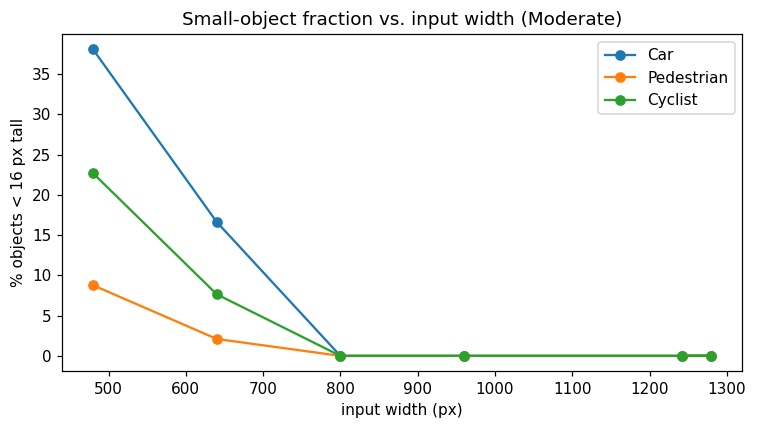

In [ ]:
widths = [480, 640, 800, 960, 1280, 1242]
rows = []
focus_mod = objs[objs.is_moderate & objs["type"].isin(FOCUS)]
for W in widths:
    s = W / 1242.0
    for c in FOCUS:
        h = focus_mod.loc[focus_mod["type"] == c, "bh"] * s
        rows.append({"input_width": W, "class": c, "median_h_px": h.median(),
                     "%_below_8px": (h < 8).mean() * 100, "%_below_16px": (h < 16).mean() * 100})
res = pd.DataFrame(rows)
print(res.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
for c in FOCUS:
    d = res[res["class"] == c]; ax.plot(d.input_width, d["%_below_16px"], marker="o", label=c)
ax.set_xlabel("input width (px)"); ax.set_ylabel("% objects < 16 px tall"); ax.set_title("Small-object fraction vs. input width (Moderate)")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Drive-grouped split (no leakage)
KITTI benchmark images are randomly shuffled, so image ids carry no temporal order. The devkit's `train_mapping.txt` and `train_rand.txt`
recover the original **raw drive** and frame for each image. We then assign **whole drives** to train / val / test (70 / 15 / 15), balancing image
and Car / Pedestrian / Cyclist counts greedily.

In [ ]:
map_df = pd.read_csv(MAP_FILE, sep=r"\s+", header=None, names=["date", "drive", "raw_frame"])
rand = [int(x) for x in RAND_FILE.read_text().replace("\n", "").split(",") if x.strip()]
print("mapping rows:", len(map_df), "| rand entries:", len(rand))
assert len(map_df) == len(rand) == len(images), "unexpected mapping size"

# benchmark image i  ->  mapping row rand[i]-1
images["_idx"] = images["image_id"].astype(int)
m = map_df.iloc[[rand[i] - 1 for i in images["_idx"]]].reset_index(drop=True)
images["drive"] = m["drive"].values
images["raw_frame"] = m["raw_frame"].astype(int).values
images = images.drop(columns="_idx")

drive_sizes = images.groupby("drive").size().sort_values(ascending=False)
print(f"{len(drive_sizes)} drives; images per drive: min {drive_sizes.min()}, median {drive_sizes.median():.0f}, max {drive_sizes.max()}")
drive_sizes.head(10)

mapping rows: 7481 | rand entries: 7481
141 drives; images per drive: min 1, median 10, max 577


,0
drive,
2011_09_26_drive_0101_sync,577
2011_09_26_drive_0022_sync,321
2011_10_03_drive_0047_sync,296
2011_09_26_drive_0064_sync,288
2011_09_26_drive_0009_sync,287
2011_09_26_drive_0061_sync,275
2011_09_26_drive_0023_sync,258
2011_09_26_drive_0096_sync,243
2011_09_26_drive_0036_sync,240


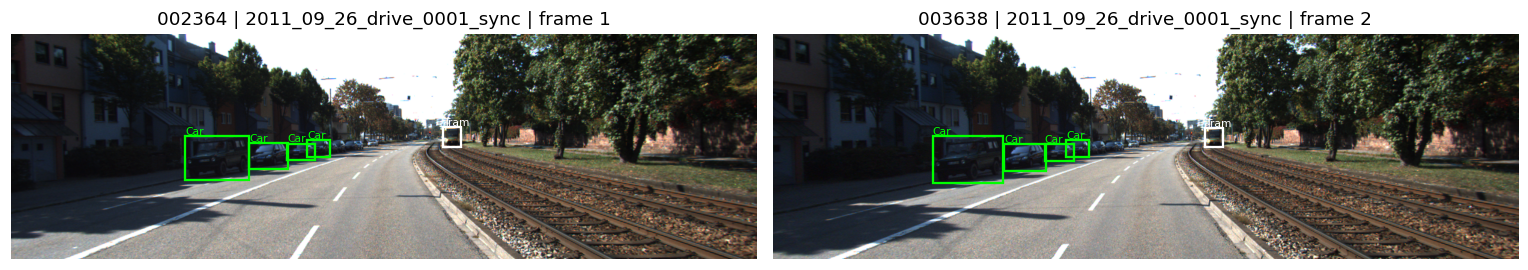

If these two frames look like consecutive moments of the same street, the mapping is correct.


In [ ]:
# Sanity check on the mapping assumption: images from the same drive with adjacent raw frames should look near-identical.
d = images.sort_values(["drive", "raw_frame"]).groupby("drive").head(2).groupby("drive").filter(lambda g: len(g) == 2)
d0 = d["drive"].iloc[0]
pair = d[d["drive"] == d0]
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
for a, r in zip(axes, pair.itertuples()):
    show_image(r.image_id, a, show_ignore=False); a.set_title(f"{r.image_id} | {r.drive} | frame {r.raw_frame}")
plt.tight_layout(); plt.show()
print("If these two frames look like consecutive moments of the same street, the mapping is correct.")

In [ ]:
def grouped_split(images, objs, ratios=(0.70, 0.15, 0.15), seed=SEED, focus=FOCUS):
    names = ["train", "val", "test"]
    feats = pd.DataFrame({"n_images": images.groupby("drive").size()})
    cnt = (objs.merge(images[["image_id", "drive"]], on="image_id")
               .groupby(["drive", "type"]).size().unstack(fill_value=0))
    for c in focus:
        feats[c] = cnt[c] if c in cnt else 0
    feats = feats.fillna(0).astype(float)
    total = feats.sum()
    target = {s: total * r for s, r in zip(names, ratios)}
    cur = {s: pd.Series(0.0, index=feats.columns) for s in names}
    cost = lambda v, t: (((v - t) / (t + 1e-9)) ** 2).sum()
    order = feats.sample(frac=1, random_state=seed).sort_values("n_images", ascending=False, kind="stable").index
    assign = {}
    for g in order:
        deltas = {s: cost(cur[s] + feats.loc[g], target[s]) - cost(cur[s], target[s]) for s in names}
        best = min(deltas, key=deltas.get)
        assign[g] = best; cur[best] = cur[best] + feats.loc[g]
    return assign

assign = grouped_split(images, objs, focus=CLASSES)   # balance all 8 classes, not just the 3 focus ones
images["split_grouped"] = images["drive"].map(assign)

# Random image-level split (ONLY for RQ3: to measure how much it inflates performance)
rs = np.random.default_rng(SEED)
perm = rs.permutation(len(images)); n = len(images)
labels = np.empty(n, dtype=object)
labels[perm[: int(.70 * n)]] = "train"; labels[perm[int(.70 * n): int(.85 * n)]] = "val"; labels[perm[int(.85 * n):]] = "test"
images["split_random"] = labels

In [ ]:
def split_report(col):
    o = objs.merge(images[["image_id", col]], on="image_id")
    t = pd.crosstab(o[col], o["type"]).reindex(["train", "val", "test"])[CLASSES]
    t.insert(0, "images", images[col].value_counts())
    t.insert(1, "drives", images.groupby(col)["drive"].nunique())
    return t

print("=== GROUPED (drive-level) split ===");  display(split_report("split_grouped"))
print("=== RANDOM (image-level) split ===");   display(split_report("split_random"))

# Hard guarantees for the grouped split
g_by_split = images.groupby("drive")["split_grouped"].nunique()
assert (g_by_split == 1).all(), "LEAK: a drive appears in more than one split"
for s in ["train", "val", "test"]:
    o = objs.merge(images[["image_id", "split_grouped"]], on="image_id")
    for c in CLASSES:
        if ((o.split_grouped == s) & (o["type"] == c)).sum() == 0:
            print(f"WARNING: {s} has no {c} (few drives). Re-run with another SEED or accept and report it.")
            assert c not in FOCUS, f"{s} has no {c}"
print("OK: no drive crosses splits; every split contains Car, Pedestrian and Cyclist.")

=== GROUPED (drive-level) split ===


type,images,drives,Car,Pedestrian,Van,Cyclist,Truck,Misc,Tram,Person_sitting
split_grouped,,,,,,,,,,
train,4699,119,18169,3165,1887,1050,579,632,321,149
val,1239,14,5081,658,468,322,398,212,140,17
test,1543,8,5492,664,559,255,117,129,50,56


=== RANDOM (image-level) split ===


type,images,drives,Car,Pedestrian,Van,Cyclist,Truck,Misc,Tram,Person_sitting
split_random,,,,,,,,,,
train,5236,139,20040,3118,2050,1194,733,693,371,138
val,1122,104,4318,650,424,230,184,148,77,31
test,1123,101,4384,719,440,203,177,132,63,53


OK: no drive crosses splits; every split contains Car, Pedestrian and Cyclist.


## 7. Leakage demonstration (supports RQ3)
For each test image in the *random* split, how close is the nearest **training** frame from the same drive? Small gaps mean near-duplicate frames
sit on both sides of the split, which will inflate test scores.

Random split : median gap to nearest train frame = 2 raw frames; 76.0% of test images have a train frame within 2 frames (~0.2 s)
Grouped split: test drives sharing train drives = 0 images (should be 0)


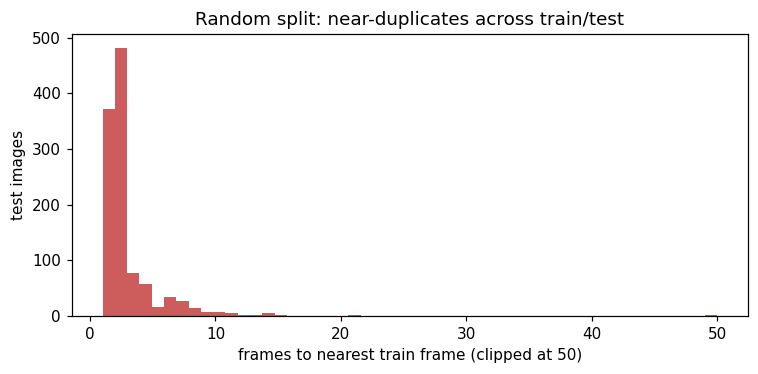

In [ ]:
def nearest_train_gap(col):
    out = []
    for drive, g in images.groupby("drive"):
        tr = g.loc[g[col] == "train", "raw_frame"].values
        te = g.loc[g[col] == "test", "raw_frame"].values
        if len(te) == 0: continue
        if len(tr) == 0:
            out += [np.inf] * len(te); continue
        out += [np.abs(tr - f).min() for f in te]
    return np.array(out)

gap_rand, gap_grp = nearest_train_gap("split_random"), nearest_train_gap("split_grouped")
print(f"Random split : median gap to nearest train frame = {np.median(gap_rand):.0f} raw frames; "
      f"{(gap_rand <= 2).mean() * 100:.1f}% of test images have a train frame within 2 frames (~0.2 s)")
print(f"Grouped split: test drives sharing train drives = {np.isfinite(gap_grp).sum()} images (should be 0)")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.clip(gap_rand, 0, 50), bins=50, color="indianred"); ax.set_xlabel("frames to nearest train frame (clipped at 50)")
ax.set_ylabel("test images"); ax.set_title("Random split: near-duplicates across train/test"); plt.tight_layout(); plt.show()

## 8. Export
### 8.1 Flat tables (framework-agnostic; usable with torchvision Faster R-CNN)

In [ ]:
ann = objs.merge(images[["image_id", "drive", "raw_frame", "split_grouped", "split_random"]], on="image_id")
ann["class_id"] = ann["type"].map({c: i for i, c in enumerate(CLASSES)})
keep = ["image_id", "type", "class_id", "x1", "y1", "x2", "y2", "width", "height", "truncated", "occluded",
        "is_easy", "is_moderate", "is_hard", "difficulty", "z3d", "drive", "raw_frame", "split_grouped", "split_random"]
ann[keep].to_csv(OUT_DIR / "annotations.csv", index=False)
images.to_csv(OUT_DIR / "images.csv", index=False)
images[["image_id", "drive", "raw_frame", "split_grouped", "split_random"]].to_csv(OUT_DIR / "splits.csv", index=False)
ignore_regions.merge(images[["image_id", "split_grouped"]], on="image_id")[["image_id", "x1", "y1", "x2", "y2", "split_grouped"]] \
              .to_csv(OUT_DIR / "ignore_regions.csv", index=False)
print("saved annotations.csv, images.csv, splits.csv, ignore_regions.csv to", OUT_DIR.resolve())

saved annotations.csv, images.csv, splits.csv, ignore_regions.csv to /content/outputs


### 8.2 YOLO format
Classes are indexed in `CLASSES` order. Boxes are written as `class cx cy w h` (normalised). `DontCare` regions are not written (they are kept in
`ignore_regions.csv` for evaluation-time handling). Images are symlinked when possible, otherwise copied. Set `SPLIT_COL = "split_random"` to export the random split for RQ3.

In [ ]:
import yaml
SPLIT_COL = "split_grouped"
YOLO_DIR = OUT_DIR / "yolo" if SPLIT_COL == "split_grouped" else OUT_DIR / "yolo_random"

def link_or_copy(src, dst):
    if dst.exists(): return
    try: os.symlink(src.resolve(), dst)
    except (OSError, NotImplementedError): shutil.copy2(src, dst)   # e.g. Windows without symlink rights

for s in ["train", "val", "test"]:
    (YOLO_DIR / "images" / s).mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / "labels" / s).mkdir(parents=True, exist_ok=True)

by_img = ann.groupby("image_id")
for r in tqdm(images.itertuples(), total=len(images), desc="YOLO export"):
    s = getattr(r, SPLIT_COL)
    link_or_copy(IMG_DIR / f"{r.image_id}.png", YOLO_DIR / "images" / s / f"{r.image_id}.png")
    lines = []
    if r.image_id in by_img.groups:
        for b in by_img.get_group(r.image_id).itertuples():
            x1, y1 = max(b.x1, 0), max(b.y1, 0)
            x2, y2 = min(b.x2, b.width), min(b.y2, b.height)
            if x2 <= x1 or y2 <= y1: continue
            lines.append(f"{b.class_id} {(x1 + x2) / 2 / b.width:.6f} {(y1 + y2) / 2 / b.height:.6f} "
                         f"{(x2 - x1) / b.width:.6f} {(y2 - y1) / b.height:.6f}")
    (YOLO_DIR / "labels" / s / f"{r.image_id}.txt").write_text("\n".join(lines))

yaml.safe_dump({"path": str(YOLO_DIR.resolve()), "train": "images/train", "val": "images/val", "test": "images/test",
                "names": {i: c for i, c in enumerate(CLASSES)}}, open(YOLO_DIR / "kitti.yaml", "w"), sort_keys=False)
print("YOLO dataset written to", YOLO_DIR.resolve())

YOLO export:   0%|          | 0/7481 [00:00<?, ?it/s]

YOLO dataset written to /content/outputs/yolo


## 9. Augmentation preview (for RQ4)
Realistic adverse-condition augmentations, applied to **training data only**. The same transforms, with a fixed seed, can be used by the evaluation
member to build the fog / rain / low-light *test* variants. Albumentations parameter names change between versions, so defaults are used here;
tune intensity after checking your installed version.

albumentations 2.0.8


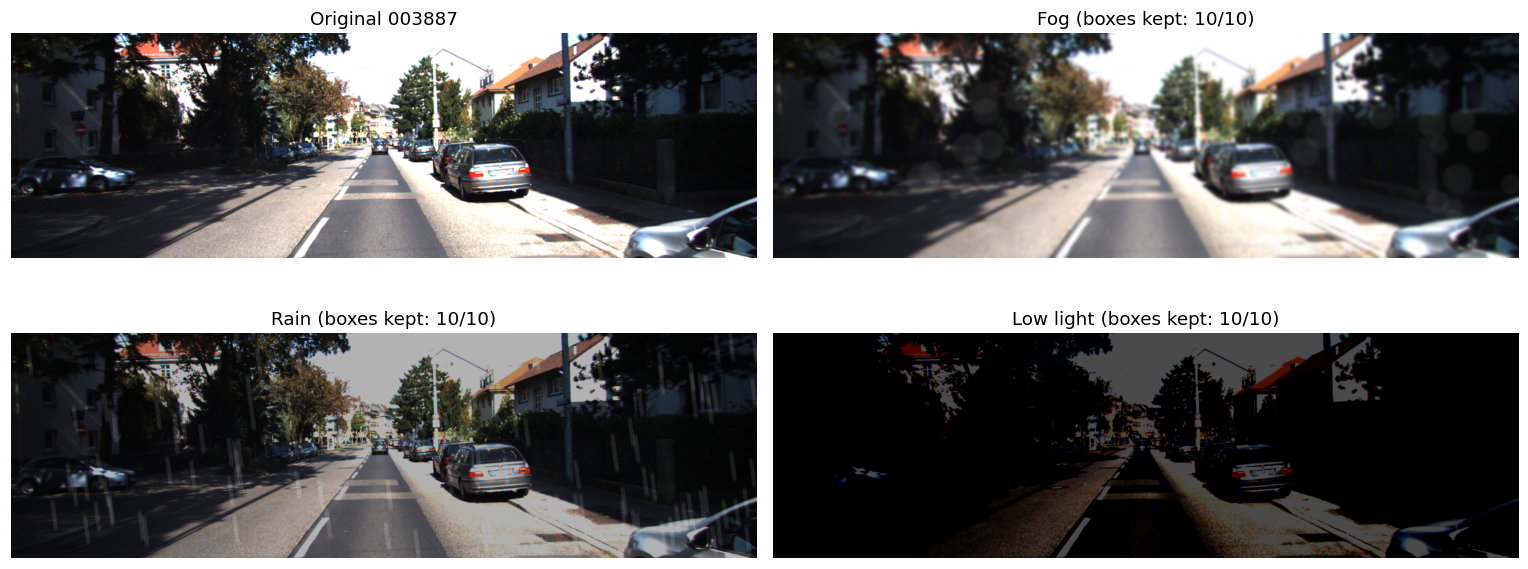

In [ ]:
import albumentations as A
print("albumentations", A.__version__)

aug = {
    "Fog":       A.Compose([A.RandomFog(p=1.0)]),
    "Rain":      A.Compose([A.RandomRain(p=1.0)]),
    "Low light": A.Compose([A.RandomBrightnessContrast(brightness_limit=(-0.55, -0.5), contrast_limit=0, p=1.0),
                            A.RandomGamma(gamma_limit=(140, 160), p=1.0)]),
}
bp = A.BboxParams(format="pascal_voc", label_fields=["labels"], min_visibility=0.3)

demo_id = rng.choice(objs[objs["type"] == "Pedestrian"]["image_id"].unique())
img = cv2.cvtColor(cv2.imread(str(IMG_DIR / f"{demo_id}.png")), cv2.COLOR_BGR2RGB)
b = objs[objs.image_id == demo_id]
boxes = b[["x1", "y1", "x2", "y2"]].clip(lower=0).values.tolist(); labels_ = b["type"].tolist()

fig, axes = plt.subplots(2, 2, figsize=(14, 6))
axes[0, 0].imshow(img); axes[0, 0].set_title(f"Original {demo_id}"); axes[0, 0].axis("off")
for a, (name, tf) in zip(axes.ravel()[1:], aug.items()):
    out = A.Compose(tf.transforms, bbox_params=bp)(image=img, bboxes=boxes, labels=labels_)
    a.imshow(out["image"]); a.set_title(f"{name} (boxes kept: {len(out['bboxes'])}/{len(boxes)})"); a.axis("off")
plt.tight_layout(); plt.show()

## 10. Summary for the team

In [ ]:
summary = {
    "n_images": int(len(images)), "n_objects": int(len(objs)), "n_ignore_regions": int(len(ignore_regions)),
    "n_drives": int(images["drive"].nunique()),
    "class_counts": objs["type"].value_counts().to_dict(),
    "difficulty_counts": objs["difficulty"].value_counts().to_dict(),
    "moderate_focus_counts": focus_mod["type"].value_counts().to_dict(),
    "split_images_grouped": images["split_grouped"].value_counts().to_dict(),
    "split_images_random": images["split_random"].value_counts().to_dict(),
    "random_split_test_within_2_frames_of_train_%": float((gap_rand <= 2).mean() * 100),
    "validation_checks": checks, "corrupt_images": int(images["corrupt"].sum()),
}
json.dump(summary, open(OUT_DIR / "eda_summary.json", "w"), indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))

{
  "n_images": 7481,
  "n_objects": 40570,
  "n_ignore_regions": 11295,
  "n_drives": 141,
  "class_counts": {
    "Car": 28742,
    "Pedestrian": 4487,
    "Van": 2914,
    "Cyclist": 1627,
    "Truck": 1094,
    "Misc": 973,
    "Tram": 511,
    "Person_sitting": 222
  },
  "difficulty_counts": {
    "Moderate": 13373,
    "Easy": 9999,
    "Unrated": 9219,
    "Hard": 7979
  },
  "moderate_focus_counts": {
    "Car": 15710,
    "Pedestrian": 3569,
    "Cyclist": 1098
  },
  "split_images_grouped": {
    "train": 4699,
    "test": 1543,
    "val": 1239
  },
  "split_images_random": {
    "train": 5236,
    "test": 1123,
    "val": 1122
  },
  "random_split_test_within_2_frames_of_train_%": 75.95725734639359,
  "validation_checks": {
    "x2 <= x1 or y2 <= y1": 0,
    "box outside image (>2px)": 0,
    "truncated outside [0,1]": 0,
    "occluded not in {0,1,2,3}": 0,
    "exact duplicate rows": 0
  },
  "corrupt_images": 0
}


### Findings to write up (fill in after running)
- Class imbalance: Car share, Person_sitting share, and the resulting need for per-class recall and possibly loss weighting or oversampling (Raiha).
- Fraction of Pedestrians / Cyclists under 16 px at candidate input widths -> pick the resolution (Section 5).
- Occlusion / truncation / difficulty mix, and how many objects the Moderate primary metric actually covers.
- Number of drives, and how well the grouped split balances classes; leakage evidence from Section 7 (feeds RQ3).
- Brightness range: confirm daytime-only data, motivating synthetic low-light augmentation (RQ4).

## 11. Fixing class imbalance and leakage
Two separate problems, so two separate fixes.

| Problem | Fix used here | Where it is applied |
|---|---|---|
| Rare classes (Cyclist, Tram, Person_sitting) are seen too rarely | **Repeat-factor sampling**: images containing rare classes are shown more often | **Train split only** |
| Near-duplicate frames and process mistakes inflate scores | Drive-grouped split (done), plus **audit**: drive overlap, near-duplicate image hashes, test-once guard | All splits (check only) |

**Why not SMOTE or class-merging?** SMOTE creates synthetic feature vectors, which makes no sense for boxes in images. Merging rare classes would change the 8-class secondary metric you promised in the proposal.
**Never** oversample before splitting: copies of one image would land in both train and test.

In [ ]:
import sys; sys.path.insert(0, ".")          # kitti files live next to this notebook
import imbalance_leakage as il

train_ids = images.loc[images.split_grouped == "train", "image_id"].tolist()
ann_train = objs[objs.image_id.isin(train_ids)]          # statistics come from TRAIN only

rf, rf_table = il.repeat_factors(ann_train, train_ids, CLASSES, t=0.3)   # t: raise for stronger oversampling
print(rf_table.round(3))
print(f"\nimage repeat factor: mean {rf.mean():.2f}, max {rf.max():.2f} -> epoch grows from {len(rf)} to ~{int(rf.sum())} images")

                img_fraction  class_repeat
Car                    0.882         1.000
Pedestrian             0.270         1.055
Van                    0.280         1.035
Cyclist                0.150         1.412
Truck                  0.120         1.582
Misc                   0.103         1.708
Tram                   0.039         2.760
Person_sitting         0.012         5.063

image repeat factor: mean 1.31, max 5.06 -> epoch grows from 4699 to ~6148 images


,before,after_RFS,boost_x
type,,,
Car,18169,23093.0,1.27
Pedestrian,3165,4969.0,1.57
Van,1887,2661.0,1.41
Cyclist,1050,1555.0,1.48
Truck,579,941.0,1.63
Misc,632,1080.0,1.71
Tram,321,1001.0,3.12
Person_sitting,149,754.0,5.06


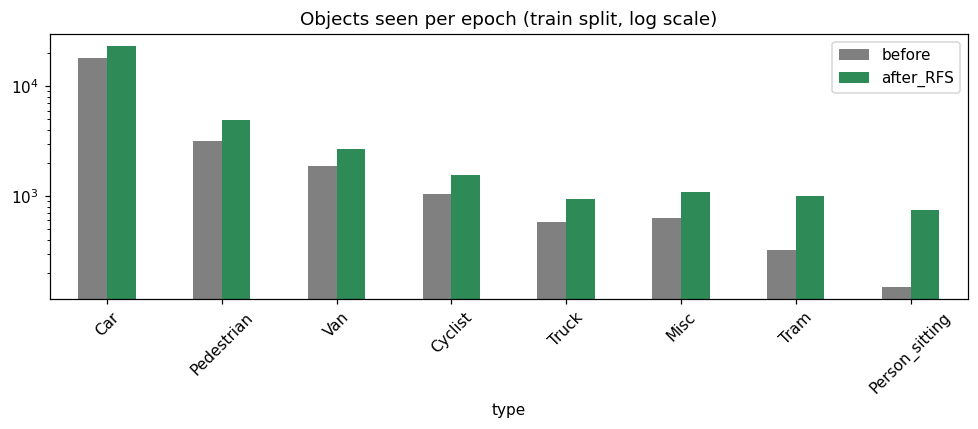

In [ ]:
before = ann_train["type"].value_counts().reindex(CLASSES).fillna(0)
after  = il.effective_class_counts(ann_train, rf, CLASSES).fillna(0)
cmp_ = pd.DataFrame({"before": before, "after_RFS": after}); cmp_["boost_x"] = (cmp_.after_RFS / cmp_.before).round(2)
display(cmp_)
cmp_[["before", "after_RFS"]].plot.bar(figsize=(9, 4), logy=True, color=["gray", "seagreen"])
plt.title("Objects seen per epoch (train split, log scale)"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

**How to use it** (pick the one that matches the model):
- **PyTorch / Faster R-CNN:** `DataLoader(train_ds, batch_size=4, sampler=il.RepeatFactorSampler(train_ds.ids, rf))`. Do not also pass `shuffle=True`. Call `sampler.set_epoch(e)` each epoch.
- **YOLO:** the cell below writes `train_rfs.txt` (repeated image paths). In `kitti.yaml` set `train: train_rfs.txt`.
- Validation and test are **never** oversampled.

In [ ]:
n_lines = il.write_yolo_oversampled_list(rf, YOLO_DIR, out_name="train_rfs.txt", seed=SEED)
print(f"wrote {YOLO_DIR/'train_rfs.txt'} with {n_lines} lines")
cfg = yaml.safe_load(open(YOLO_DIR / "kitti.yaml")); cfg["train"] = "train_rfs.txt"
yaml.safe_dump(cfg, open(YOLO_DIR / "kitti_rfs.yaml", "w"), sort_keys=False)
print("use data=", YOLO_DIR / "kitti_rfs.yaml")

wrote outputs/yolo/train_rfs.txt with 6157 lines
use data= outputs/yolo/kitti_rfs.yaml


### Evaluation side of imbalance
Oversampling fixes *training*. For *evaluation*, never report overall accuracy. Report **per-class AP and recall**, plus the 8-class mean, and keep the test set's natural class mix (do not rebalance it).

### Leakage audit
The drive-grouped split already stops neighbouring frames from crossing sets. The audit below proves it, and also looks for **near-identical images from different drives** (for example a car waiting at the same junction), which the drive split cannot see.

In [ ]:
audit = il.audit_leakage(images, split_col="split_grouped", required_classes=CLASSES, objs=objs)
print(audit)          # raises AssertionError if a drive or image crosses splits

{'drives_in_multiple_splits': 0, 'image_id_overlap': 0, 'classes_missing_per_split': {}}


In [ ]:
hashes = il.compute_hashes(IMG_DIR, images["image_id"].tolist())
twins = il.cross_split_near_duplicates(images, hashes, "split_grouped", max_bits=4)
print(f"val/test images with a near-identical TRAIN image: {len(twins)} of {(images.split_grouped != 'train').sum()}")
display(twins.head(10))

val/test images with a near-identical TRAIN image: 66 of 2782


,split,image_id,twin_train_id,hamming,same_drive
0,val,000058,001444,0,False
1,val,000199,000598,1,False
2,val,000324,000193,1,False
3,val,000398,000193,1,False
4,val,000499,007306,4,False
5,val,000862,001205,2,False
6,val,000947,001406,0,False
7,val,001019,007306,4,False
8,val,001028,000045,4,False
9,val,001088,000294,0,False


**If `twins` is not empty:** look at a few pairs with `show_image`. For true duplicates, drop those val/test images (or move the whole offending drive into train), then re-run from the split cell.
**Optional stricter check:** group by recording *date* (`images.drive.str[:10]`) instead of drive. Fewer groups means a less balanced split, but it removes shared-location similarity. Use it as a robustness experiment, not the default.

In [ ]:
# Process rules that prevent leakage (checklist, enforced by code where possible)
# 1. Mean/std normalisation, class weights, repeat factors: computed on train only  (done above)
# 2. Augmentation: only in the train Dataset; val/test get transform=None
# 3. Hyperparameters and early stopping: decided on val only
# 4. Test set: opened once, at the very end
guard = il.TestSetGuard("outputs/.test_used")
# at the very end of the project, in the final evaluation script:
#     guard.acquire("final evaluation of chosen model")     # a second call raises RuntimeError